# Explainable Machine Learning for Gallstone Disease

## Libraries

In [53]:
import pandas as pd
import numpy as np
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, validation_curve, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, recall_score, precision_score, confusion_matrix, classification_report, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

### 1.1 Dataset

In [54]:
gd_df = pd.read_csv("dataset-uci.csv")

## 2. Data Exploration

### 2.1 Initial Data Review

In [55]:
gd_df.head(10).T

,0,1,2,3,4,5,6,7,8,9
Gallstone Status,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Age,50.00,47.00,61.00,41.00,42.00,96.00,37.00,41.00,38.00,38.00
Gender,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Comorbidity,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Coronary Artery Disease (CAD),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Hypothyroidism,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Hyperlipidemia,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Diabetes Mellitus (DM),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Height,185.00,176.00,171.00,168.00,178.00,155.00,185.00,176.00,186.00,171.00
Weight,92.80,94.50,91.10,67.70,89.60,49.00,67.10,114.00,93.70,68.60


In [56]:
gd_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 39 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Gallstone Status                                319 non-null    int64  
 1   Age                                             319 non-null    int64  
 2   Gender                                          319 non-null    int64  
 3   Comorbidity                                     319 non-null    int64  
 4   Coronary Artery Disease (CAD)                   319 non-null    int64  
 5   Hypothyroidism                                  319 non-null    int64  
 6   Hyperlipidemia                                  319 non-null    int64  
 7   Diabetes Mellitus (DM)                          319 non-null    int64  
 8   Height                                          319 non-null    int64  
 9   Weight                                          319 no

In [57]:
gd_df.shape

(319, 39)

In [58]:
gd_df.isnull().sum()

Gallstone Status                                  0
Age                                               0
Gender                                            0
Comorbidity                                       0
Coronary Artery Disease (CAD)                     0
Hypothyroidism                                    0
Hyperlipidemia                                    0
Diabetes Mellitus (DM)                            0
Height                                            0
Weight                                            0
Body Mass Index (BMI)                             0
Total Body Water (TBW)                            0
Extracellular Water (ECW)                         0
Intracellular Water (ICW)                         0
Extracellular Fluid/Total Body Water (ECF/TBW)    0
Total Body Fat Ratio (TBFR) (%)                   0
Lean Mass (LM) (%)                                0
Body Protein Content (Protein) (%)                0
Visceral Fat Rating (VFR)                         0
Bone Mass (B

$$\boxed{\text{No null values found}}$$

In [59]:
gd_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Gallstone Status,319.0,0.495298,0.500763,0.00,0.000,0.000000,1.000,1.00
Age,319.0,48.068966,12.114558,20.00,38.500,49.000000,56.000,96.00
Gender,319.0,0.492163,0.500724,0.00,0.000,0.000000,1.000,1.00
Comorbidity,319.0,0.335423,0.517340,0.00,0.000,0.000000,1.000,3.00
Coronary Artery Disease (CAD),319.0,0.037618,0.190568,0.00,0.000,0.000000,0.000,1.00
Hypothyroidism,319.0,0.028213,0.165841,0.00,0.000,0.000000,0.000,1.00
Hyperlipidemia,319.0,0.025078,0.156609,0.00,0.000,0.000000,0.000,1.00
Diabetes Mellitus (DM),319.0,0.134796,0.342042,0.00,0.000,0.000000,0.000,1.00
Height,319.0,167.156740,10.053030,145.00,159.500,168.000000,175.000,191.00
Weight,319.0,80.564890,15.709069,42.90,69.600,78.800000,91.250,143.50


In [60]:
gd_df.describe().T.sort_values("std", ascending=False)

,count,mean,std,min,25%,50%,75%,max
Obesity (%),319.0,35.850125,109.799718,0.40,13.900,25.600000,41.750,1954.00
Triglyceride,319.0,144.502163,97.904493,1.39,83.000,119.000000,172.000,838.00
Total Cholesterol (TC),319.0,203.495298,45.758501,60.00,172.000,198.000000,233.000,360.00
Glucose,319.0,108.688715,44.848714,69.00,92.000,98.000000,109.000,575.00
Low Density Lipoprotein (LDL),319.0,126.652351,38.541175,11.00,100.500,122.000000,151.000,293.00
Alanin Aminotransferaz (ALT),319.0,26.855799,27.884413,3.00,14.250,19.000000,30.000,372.00
Alkaline Phosphatase (ALP),319.0,73.112539,24.181069,7.00,58.000,71.000000,86.000,197.00
High Density Lipoprotein (HDL),319.0,49.475549,17.718701,25.00,40.000,46.500000,56.000,273.00
Glomerular Filtration Rate (GFR),319.0,100.818903,16.971396,10.60,94.170,104.000000,110.745,132.00
Aspartat Aminotransferaz (AST),319.0,21.684953,16.697605,8.00,15.000,18.000000,23.000,195.00


In [61]:
gd_df.duplicated().sum()

np.int64(0)

C:\Users\esoey\AppData\Local\Temp\ipykernel_24236\2251986942.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Present", "Absent"])


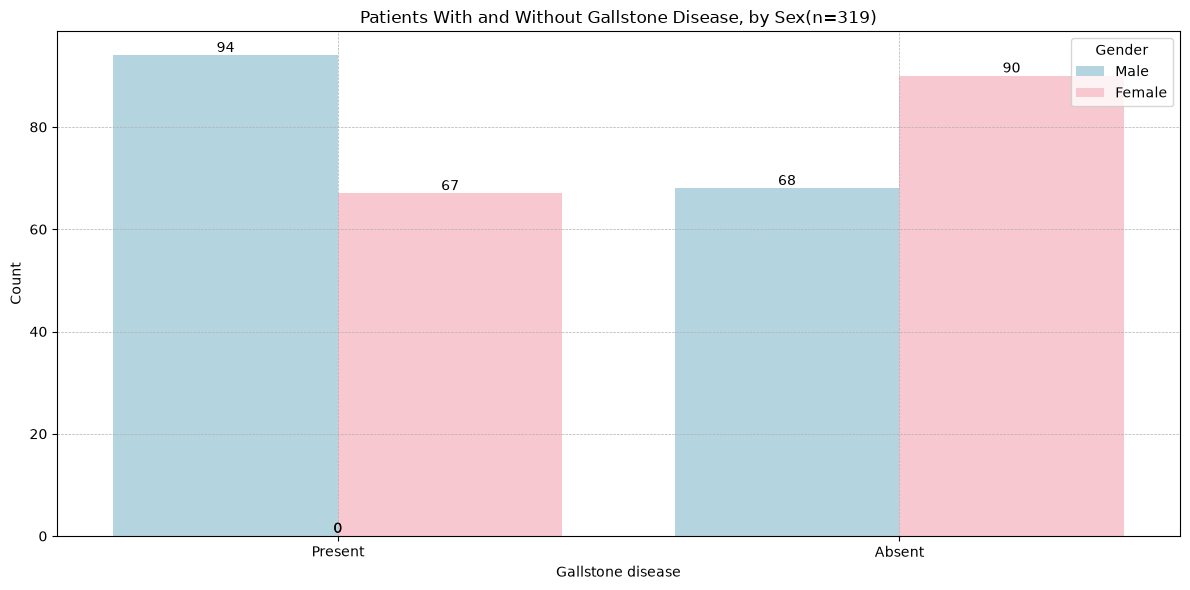

In [62]:
plt.figure(figsize=(12, 6))
plt.title("Patients With and Without Gallstone Disease, by Sex(n=319)")
ax = sns.countplot(x = "Gallstone Status", hue="Gender", data = gd_df, palette= ("lightblue", "pink"))
ax.set_xticklabels(["Present", "Absent"])

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.xlabel("Gallstone disease")
plt.ylabel("Count")
plt.tight_layout()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.legend(title="Gender", loc="upper right", labels=["Male", "Female"])
plt.show()

After inspecting the dataset statistics (describe()) we noticed obesity had a large standard deviation. This should be taken a closer look at later.

In [63]:
gd_df[["Obesity (%)", "Height", "Weight"]].sort_values("Obesity (%)", ascending=False).head() # anomaly ? 

,Obesity (%),Height,Weight
239,1954.00,150,65.9
23,125.60,170,143.5
209,106.30,150,102.1
280,96.63,150,108.4
246,95.64,162,125.8


In [64]:
gd_df[["Triglyceride", "Height", "Weight"]].sort_values("Triglyceride", ascending=False).head() # anomaly ? 

,Triglyceride,Height,Weight
242,838.0,173,87.8
20,692.0,178,110.7
8,679.0,186,93.7
7,464.0,176,114.0
50,455.0,167,82.2


After inspecting the dataset statistics (describe()) we noticed obesity had a large standard deviation. This should be taken a closer look at later.

### 2.3 Visualization

C:\Users\esoey\AppData\Local\Temp\ipykernel_24236\2251986942.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Present", "Absent"])


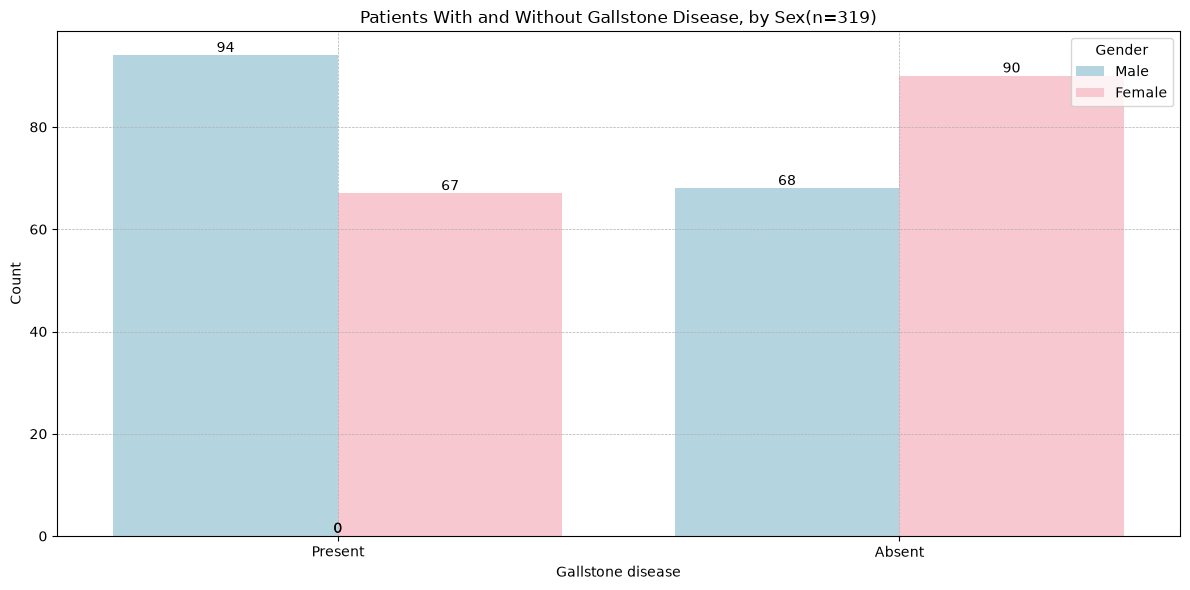

In [65]:
plt.figure(figsize=(12, 6))
plt.title("Patients With and Without Gallstone Disease, by Sex(n=319)")
ax = sns.countplot(x = "Gallstone Status", hue="Gender", data = gd_df, palette= ("lightblue", "pink"))
ax.set_xticklabels(["Present", "Absent"])

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.xlabel("Gallstone disease")
plt.ylabel("Count")
plt.tight_layout()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.legend(title="Gender", loc="upper right", labels=["Male", "Female"])
plt.show()

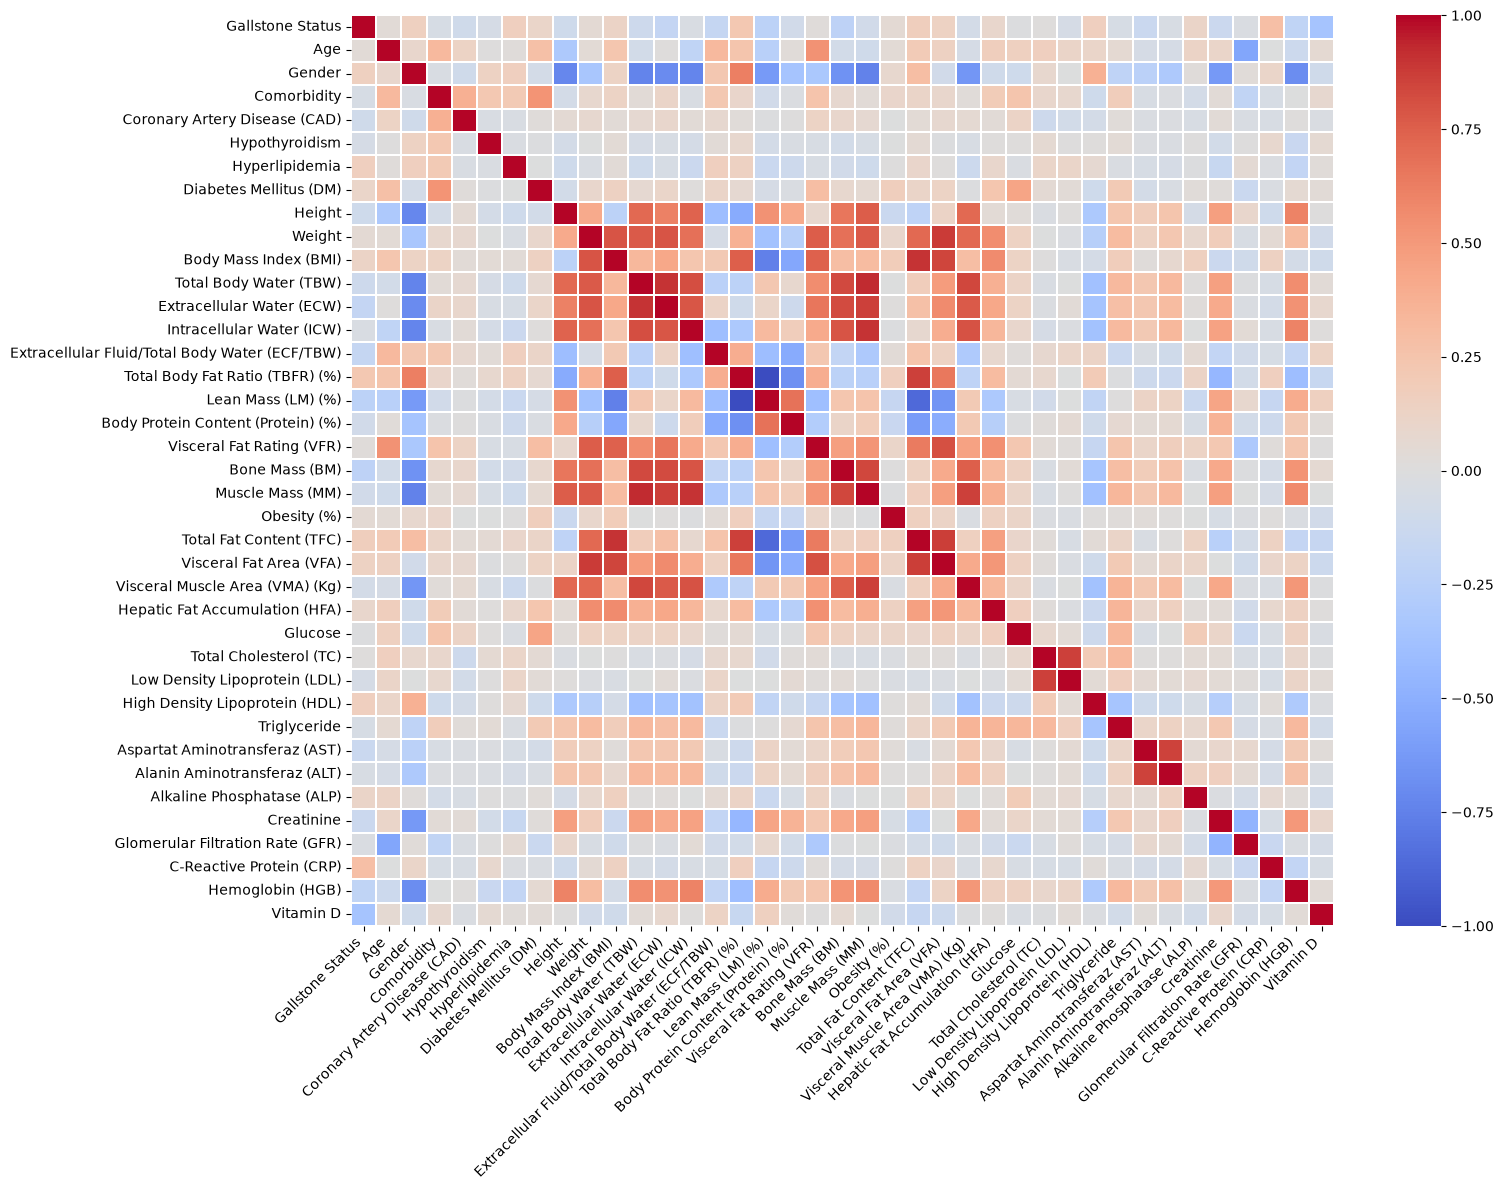

In [66]:
plt.figure(figsize=(16, 12))
sns.heatmap(gd_df.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

In [67]:
gd_df[["Gallstone Status", "C-Reactive Protein (CRP)"]].sort_values("C-Reactive Protein (CRP)", ascending=False).T

,214,272,231,153,270,268,257,280,277,208,...,35,34,2,309,313,1,315,316,0,318
Gallstone Status,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0
C-Reactive Protein (CRP),43.4,36.7,36.1,31.0,24.5,21.4,18.8,16.5,14.0,13.9,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [68]:
no_gallstone = gd_df[gd_df["Gallstone Status"] == 1]
no_gallstone.describe().T

,count,mean,std,min,25%,50%,75%,max
Gallstone Status,158.0,1.000000,0.000000,1.00,1.000000,1.000000,1.000000,1.00
Age,158.0,48.512658,11.200397,20.00,39.250000,50.000000,56.000000,76.00
Gender,158.0,0.569620,0.496704,0.00,0.000000,1.000000,1.000000,1.00
Comorbidity,158.0,0.310127,0.464016,0.00,0.000000,0.000000,1.000000,1.00
Coronary Artery Disease (CAD),158.0,0.018987,0.136914,0.00,0.000000,0.000000,0.000000,1.00
Hypothyroidism,158.0,0.018987,0.136914,0.00,0.000000,0.000000,0.000000,1.00
Hyperlipidemia,158.0,0.050633,0.219944,0.00,0.000000,0.000000,0.000000,1.00
Diabetes Mellitus (DM),158.0,0.170886,0.377606,0.00,0.000000,0.000000,0.000000,1.00
Height,158.0,166.063291,10.247065,146.00,158.000000,165.000000,174.000000,191.00
Weight,158.0,81.335443,15.444613,42.90,70.225000,79.850000,92.150000,125.80


In [69]:
has_gallstone = gd_df[gd_df["Gallstone Status"] == 0]
has_gallstone.describe().T

,count,mean,std,min,25%,50%,75%,max
Gallstone Status,161.0,0.000000,0.000000,0.00,0.000,0.00,0.00,0.00
Age,161.0,47.633540,12.969527,20.00,38.000,49.00,56.00,96.00
Gender,161.0,0.416149,0.494457,0.00,0.000,0.00,1.00,1.00
Comorbidity,161.0,0.360248,0.565164,0.00,0.000,0.00,1.00,3.00
Coronary Artery Disease (CAD),161.0,0.055901,0.230447,0.00,0.000,0.00,0.00,1.00
Hypothyroidism,161.0,0.037267,0.190007,0.00,0.000,0.00,0.00,1.00
Hyperlipidemia,161.0,0.000000,0.000000,0.00,0.000,0.00,0.00,0.00
Diabetes Mellitus (DM),161.0,0.099379,0.300104,0.00,0.000,0.00,0.00,1.00
Height,161.0,168.229814,9.771929,145.00,162.000,170.00,175.00,188.00
Weight,161.0,79.808696,15.976226,47.30,69.200,78.00,90.50,143.50


In [70]:
gd_df.corrwith(gd_df["Gallstone Status"])

Gallstone Status                                  1.000000
Age                                               0.036339
Gender                                            0.153483
Comorbidity                                      -0.048516
Coronary Artery Disease (CAD)                    -0.096998
Hypothyroidism                                   -0.055196
Hyperlipidemia                                    0.161901
Diabetes Mellitus (DM)                            0.104689
Height                                           -0.107919
Weight                                            0.048669
Body Mass Index (BMI)                             0.121507
Total Body Water (TBW)                           -0.111233
Extracellular Water (ECW)                        -0.178436
Intracellular Water (ICW)                        -0.035274
Extracellular Fluid/Total Body Water (ECF/TBW)   -0.169826
Total Body Fat Ratio (TBFR) (%)                   0.225470
Lean Mass (LM) (%)                               -0.2257

### 2.4 Preprocessing

Make decisions regarding the label, handle outliers, and train/test split

In [71]:
X = gd_df.drop(["Gallstone Status"], axis = 1)
y = gd_df["Gallstone Status"]

#### Train/Test Split

In [72]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

### 2.5 Feature Selection

Look at high-correlation pairs, mutual information, drop table, ANOVA F-score, and decide which features to keep and which to drop.

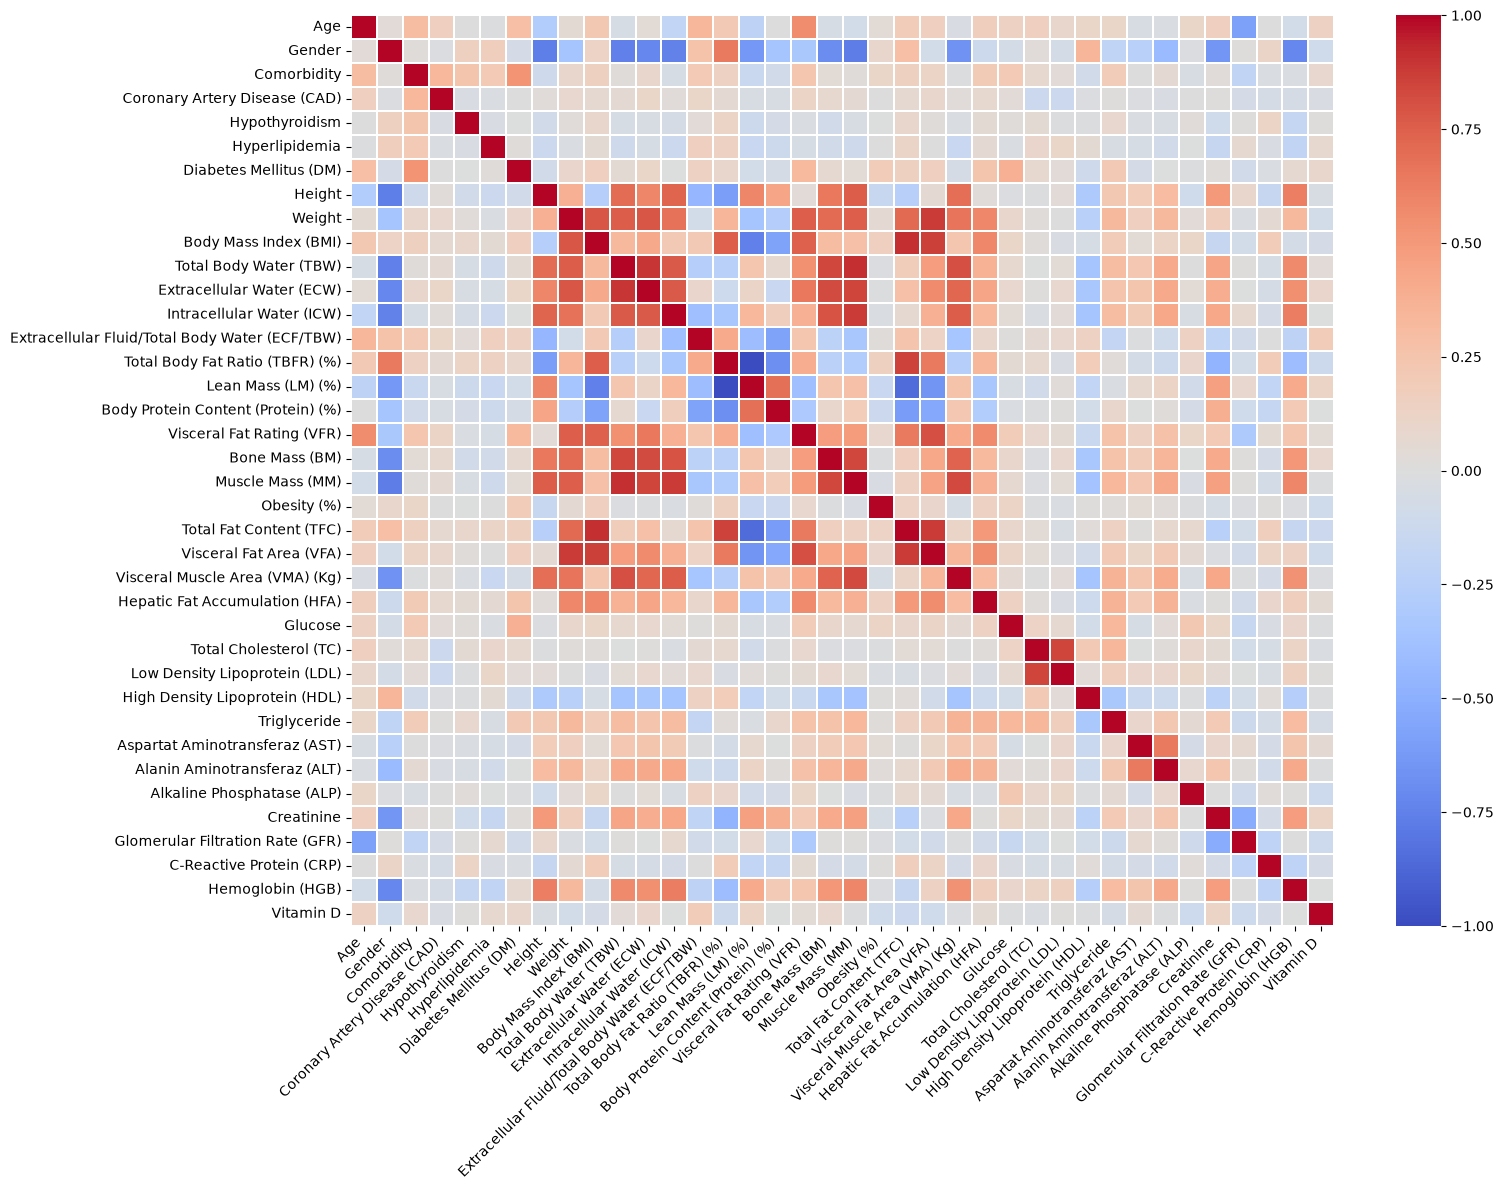

In [73]:
plt.figure(figsize=(16, 12))
sns.heatmap(X_train.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

In [74]:
# correlation values between features
corr = X_train.corr().abs()

corr = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

high_corr = corr[(corr > 0.8) & (corr != 1)].stack()

high_corr.sort_values(ascending=False)

Total Body Fat Ratio (TBFR) (%)  Lean Mass (LM) (%)                  0.997281
Body Mass Index (BMI)            Total Fat Content (TFC)             0.911075
Total Body Water (TBW)           Muscle Mass (MM)                    0.909207
                                 Extracellular Water (ECW)           0.895508
Total Fat Content (TFC)          Visceral Fat Area (VFA)             0.881455
                                                                       ...   
Vitamin D                        Creatinine                               NaN
                                 Glomerular Filtration Rate (GFR)         NaN
                                 C-Reactive Protein (CRP)                 NaN
                                 Hemoglobin (HGB)                         NaN
                                 Vitamin D                                NaN
Length: 1444, dtype: float64

In [75]:
X_train[["Total Body Fat Ratio (TBFR) (%)", "Lean Mass (LM) (%)"]].corr()

,Total Body Fat Ratio (TBFR) (%),Lean Mass (LM) (%)
Total Body Fat Ratio (TBFR) (%),1.000000,-0.997281
Lean Mass (LM) (%),-0.997281,1.000000


In [76]:
mutual_info = mutual_info_classif(X_train, y_train, random_state=1)
mutual_info = pd.Series(mutual_info, index = X_train.columns).sort_values(ascending=False)
mutual_info

C-Reactive Protein (CRP)                          0.162320
Extracellular Water (ECW)                         0.149400
Body Protein Content (Protein) (%)                0.107990
Vitamin D                                         0.107470
Visceral Muscle Area (VMA) (Kg)                   0.061865
Intracellular Water (ICW)                         0.057925
Extracellular Fluid/Total Body Water (ECF/TBW)    0.055065
Muscle Mass (MM)                                  0.051326
Alkaline Phosphatase (ALP)                        0.048281
Total Cholesterol (TC)                            0.046538
Body Mass Index (BMI)                             0.044508
Visceral Fat Rating (VFR)                         0.038315
Lean Mass (LM) (%)                                0.029304
Triglyceride                                      0.026929
Total Body Fat Ratio (TBFR) (%)                   0.020534
Aspartat Aminotransferaz (AST)                    0.017612
Visceral Fat Area (VFA)                           0.0149

In [77]:
drop_features = ["Total Body Water (TBW)", "Lean Mass (LM) (%)", "Obesity (%)"] # justification in feature_selection.md

X_train_selected = X_train.drop(columns=drop_features)
X_valid_selected = X_valid.drop(columns=drop_features)
X_test_selected = X_test.drop(columns=drop_features)

# now only 35 features
print(X_train_selected.shape)
print(X_test_selected.shape)

(223, 35)
(48, 35)


In [91]:
SEED = 132

models = {
    "Logistic Regression" : Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=SEED))
    ]),

    "Random Forest" : Pipeline([
        ("model", RandomForestClassifier(n_estimators=300, random_state=SEED))
        ]),

    "KNN" : Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "SVM" : Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=SEED))]),

    "Gradient Boost" : Pipeline([
    ("model", GradientBoostingClassifier(n_estimators=300, random_state=SEED))
    ])
}

In [90]:
results = []

for name, clf in models.items():
    clf.fit(X_train_selected, y_train)
    y_pred = clf.predict(X_valid_selected)
    y_prob = clf.predict_proba(X_valid_selected)[:,1]

    results.append({
        "model": name,
        "roc_auc": roc_auc_score(y_valid, y_prob),
        "accuracy": accuracy_score(y_valid, y_pred),
        "recall": recall_score(y_valid, y_pred),
        "precision": precision_score(y_valid, y_pred),
        "recall": recall_score(y_valid, y_pred),
        "f1": f1_score(y_valid, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("roc_auc", ascending=False)
results_df

c:\Users\esoey\Documents\M-DATSCI-2026V\DAT540 Introduction to Data Science\DAT540-Project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,model,roc_auc,accuracy,recall,precision,f1
4,Gradient Boost,0.899306,0.833333,0.833333,0.833333,0.833333
1,Random Forest,0.873264,0.812500,0.791667,0.826087,0.808511
0,Logistic Regression,0.861111,0.750000,0.750000,0.750000,0.750000
3,SVM,0.822917,0.687500,0.625000,0.714286,0.666667
2,KNN,0.732639,0.729167,0.583333,0.823529,0.682927


c:\Users\esoey\Documents\M-DATSCI-2026V\DAT540 Introduction to Data Science\DAT540-Project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\esoey\Documents\M-DATSCI-2026V\DAT540 Introduction to Data Science\DAT540-Project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnin

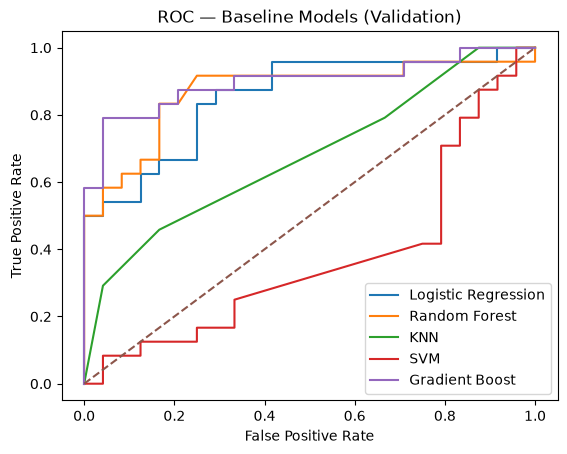

In [92]:
plt.figure()
for name in models.keys():
    # Refit to ensure we have the trained instance here (for clarity)
    match name:
        case "Logistic Regression":
            clf = LogisticRegression(max_iter=1000, random_state=42)
        case "Random Forest":
            clf = RandomForestClassifier(n_estimators=300, random_state=42)
        case "KNN":
            clf = KNeighborsClassifier(n_neighbors=5)
        case "SVM":
            clf = SVC(probability=True, random_state=42)
        case "Gradient Boost":
            clf = GradientBoostingClassifier(n_estimators=300, random_state=42)
        case _:
            raise ValueError(f"Unknown model name: {name}")

    clf.fit(X_train, y_train)
    if hasattr(clf, "predict_proba"):
        y_prob = clf.predict_proba(X_valid)[:,1]
        fpr, tpr, _ = roc_curve(y_valid, y_prob)
        plt.plot(fpr, tpr, label=name)
    elif hasattr(clf, "decision_function"):
        scores = clf.decision_function(X_valid)
        # normalize to [0,1] to plot ROC
        s = (scores - scores.min())/(scores.max()-scores.min()+1e-9)
        fpr, tpr, _ = roc_curve(y_valid, s)
        plt.plot(fpr, tpr, label=name)

plt.plot([0,1],[0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC — Baseline Models (Validation)")
plt.legend()
plt.show()

### Noe om model selection??

In [80]:
F_vals, p_vals = f_classif(X_train_selected, y_train)
feature_names = X_train_selected.columns

assert len(feature_names) == len(F_vals)

f_table = pd.DataFrame({
    "feature": feature_names,
    "F_score": F_vals,
    "p_value": p_vals
}).sort_values("F_score", ascending=False)

# ANOVA F-score Analysis Summary
print("="*60)
print("ANALYSIS OF VARIANCE (ANOVA) F-SCORE ANALYSIS")
print("="*60)
print(f"\nTotal features analyzed: {len(F_vals)}")
print(f"F-score range: {F_vals.min():.3f} to {F_vals.max():.3f}")
print(f"Mean F-score: {F_vals.mean():.3f}")
print(f"Median F-score: {np.median(F_vals):.3f}")
print(f"Std deviation: {F_vals.std():.3f}")
print(f"\nFeatures with F >= 1.0: {(F_vals >= 1.0).sum()}")
print(f"Features with F >= 0.70: {(F_vals >= 0.70).sum()}")

print(f"Features with p < 0.001: {(p_vals < 0.001).sum()} (extremely significant) (***)")
print(f"Features with p < 0.01: {(p_vals < 0.01).sum()} (highly significant) (**)")
print(f"Features with p < 0.05: {(p_vals < 0.05).sum()} (statistically significant) (*)")

print("\n" + "="*60)
print("TOP FEATURES BY ANOVA F-SCORE")
print("="*60)
for _, row in f_table.iterrows():
    significance = "***" if row['p_value'] < 0.001 else "**" if row['p_value'] < 0.01 else "*" if row['p_value'] < 0.05 else ""
    print(f"{row['feature']:<35} F={row['F_score']:>8.3f}  p={row['p_value']:.4e} {significance}")

print("\nSignificance: (***) p<0.001, (**) p<0.01, (*) p<0.05")

# Select features
selected_df = f_table[f_table["F_score"] >= 0.70]
selected_features = selected_df["feature"].tolist()

print(f"\nSelected {len(selected_features)} features (F >= 0.70):")
for i, row in enumerate(selected_df.itertuples(), 1):
    print(f"{i:2d}. {row.feature:<35} (F={row.F_score:.3f})")

# Transform the data
X_train_anova = X_train_selected[selected_features]    
X_valid_anova = X_valid_selected[selected_features]

print(f"\nOriginal features: {X_train_selected.shape[1]}")
print(f"Selected features: {X_train_selected.shape[1]}")

# Compare baseline model performance with feature selection
print("\n" + "="*60)
print("Performance Comparison: All Features vs. Feature Selection")
print("="*60)

for name, clf in models.items():
    clf_all = clone(clf)
    clf_selected = clone(clf)

    clf_all.fit(X_train_selected, y_train)
    y_pred_all = clf_all.predict_proba(X_valid_selected)[: ,1]
    roc_auc_all = roc_auc_score(y_valid, y_pred_all)

    clf_selected.fit(X_train_anova, y_train)
    y_pred_selected = clf_selected.predict_proba(X_valid_anova)[: ,1]
    roc_auc_selected = roc_auc_score(y_valid, y_pred_selected)

    print(f"\n{name}:")
    print(f"  All features ({X_train_selected.shape[1]}):      ROC-AUC = {roc_auc_all:.4f}")
    print(f"  Selected features ({len(selected_features)}):  ROC-AUC = {roc_auc_selected:.4f}")
    print(f"  Difference:                {roc_auc_selected - roc_auc_all:+.4f}")

ANALYSIS OF VARIANCE (ANOVA) F-SCORE ANALYSIS

Total features analyzed: 35
F-score range: 0.000 to 30.760
Mean F-score: 4.194
Median F-score: 2.729
Std deviation: 5.965

Features with F >= 1.0: 23
Features with F >= 0.70: 24
Features with p < 0.001: 3 (extremely significant) (***)
Features with p < 0.01: 6 (highly significant) (**)
Features with p < 0.05: 12 (statistically significant) (*)

TOP FEATURES BY ANOVA F-SCORE
Vitamin D                           F=  30.760  p=8.2998e-08 ***
C-Reactive Protein (CRP)            F=  17.219  p=4.7533e-05 ***
Bone Mass (BM)                      F=  13.360  p=3.2124e-04 ***
Extracellular Water (ECW)           F=   8.695  p=3.5340e-03 **
Total Body Fat Ratio (TBFR) (%)     F=   8.312  p=4.3280e-03 **
Aspartat Aminotransferaz (AST)      F=   7.908  p=5.3631e-03 **
Hyperlipidemia                      F=   6.461  p=1.1713e-02 *
High Density Lipoprotein (HDL)      F=   5.824  p=1.6623e-02 *
Visceral Muscle Area (VMA) (Kg)     F=   4.486  p=3.5288e-02 *


c:\Users\esoey\Documents\M-DATSCI-2026V\DAT540 Introduction to Data Science\DAT540-Project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\esoey\Documents\M-DATSCI-2026V\DAT540 Introduction to Data Science\DAT540-Project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Gradient Boost:
  All features (35):      ROC-AUC = 0.8993
  Selected features (24):  ROC-AUC = 0.9184
  Difference:                +0.0191


## 3. Model Selection

### 3.1 Research Question

**Example:** How can we design a model with a high prediction of gallstone disease?

### 3.2 Model Justification

#### Logistic Regession 
Logistic Regression was selected as a baseline model because it is simple and easy to interpret. It estimates the probability of gallstone disease based on the input features, providing a useful comparison for more comlex models. 

#### Random Forest
Random Forest combines multiple dicision trees to make predictions. It was selected because it can capture nonlinear information between features. 

#### Gradient Boost
Gradient Boosting build decision trees(scikit-learn default) sequentially, where each new tree attempts to improve the predictions of the existing model. It was selected to investigate whether the approach could improve predictive performance compared to Random Forest and the simpler models. 

#### SVM (Support Vector Machine)
SVM tries to find the best dividing line that separates the different classes, with as much space between them as possible. It was selected because it can perform well on small datasets. The Radial Basis Function(RBF) kernel, wich is used by default in sckikit-learn, allows the model find nonlinear pattern between the features and gallstone disease. 

#### KNN (K-Nearest Neightbors)
KNN predicts a new observation based on its closest training observations. It was selected as a simple distance-based approach to investigate whether patients with similar characteristics also tend to have similar gallstone outcomes. 

**Justification of model selection**

## 4. Training

### 4.1 Data Preparation

Pipelines, cross-validation

In [82]:
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC-AUC": "roc_auc"
}

In [83]:
cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

### 4.2 Cross-validation Results

In [ ]:
results = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train_selected,
        y_train,
        cv=cross_validation,
        scoring=scoring
    )

    results[name] = scores

c:\Users\esoey\Documents\M-DATSCI-2026V\DAT540 Introduction to Data Science\DAT540-Project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\esoey\Documents\M-DATSCI-2026V\DAT540 Introduction to Data Science\DAT540-Project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\esoey\Documents\M-DATSCI-2026V\DAT540 Introduction to Data Science\DAT540-Project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of 

### Results of 5-fold with 35 features

In [ ]:
comparison = pd.DataFrame()

for name, scores in results.items():
    for metric in scoring:
        mean = scores[f"test_{metric}"].mean()
        sd = scores[f"test_{metric}"].std()

        comparison.loc[name, metric] = f"{mean: .3f} ± {sd: .3f}"

display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.740 ± 0.053,0.752 ± 0.059,0.709 ± 0.098,0.726 ± 0.065,0.847 ± 0.057
Random Forest,0.762 ± 0.088,0.766 ± 0.113,0.764 ± 0.088,0.761 ± 0.084,0.826 ± 0.098
KNN,0.619 ± 0.037,0.698 ± 0.152,0.464 ± 0.060,0.544 ± 0.027,0.680 ± 0.056
SVM,0.730 ± 0.078,0.773 ± 0.095,0.645 ± 0.101,0.701 ± 0.092,0.796 ± 0.086
Gradient Boost,0.735 ± 0.072,0.747 ± 0.087,0.718 ± 0.113,0.726 ± 0.075,0.821 ± 0.078


In [ ]:
print(results["Gradient Boost"]["test_ROC-AUC"])

[0.85375494 0.94466403 0.7312253  0.83057851 0.74380165]


### 5.1 Metrics

### 5.2 Parameter Tuning

In [ ]:
# Grid search function
def grid_search(model: str, param_grid: dict, score: str = "roc_auc"):
    '''
    Tune one model's hyperparameters with cross-validated grid search.

    Every combination in param_grid is tried with stratified 5-fold CV on the training set, scored by ROC-AUC. Prints the best parameters and their mean CV score.

    Parameters:
        model (str): Name of a model in the `models` dict, e.g. "Logistic Regression" or "KNN".
        param_grid (dict): Hyperparameters to try. Keys use the pipeline prefix, e.g. {"model__C": [0.01, 0.1, 1, 10]}.
        score (str): Metric used to rank the grid combinations, e.g. "roc_auc" or "recall". Default "roc_auc".
    '''

    grid_search = GridSearchCV(estimator=models[model],
                            param_grid=param_grid,
                            cv=cross_validation,
                            scoring=score,
                            return_train_score=True)

    grid_search.fit(X_train_selected, y_train)

    print("Best parameters: ", grid_search.best_params_)
    print("Best score: ", grid_search.best_score_)

    return grid_search

In [ ]:
param_grid= {
    "model__C" : [0.01, 0.1, 1, 10, 100]
    }

grid_search = grid_search("Logistic Regression", param_grid=param_grid)

Best parameters:  {'model__C': 1}
Best score:  0.8472511678045276


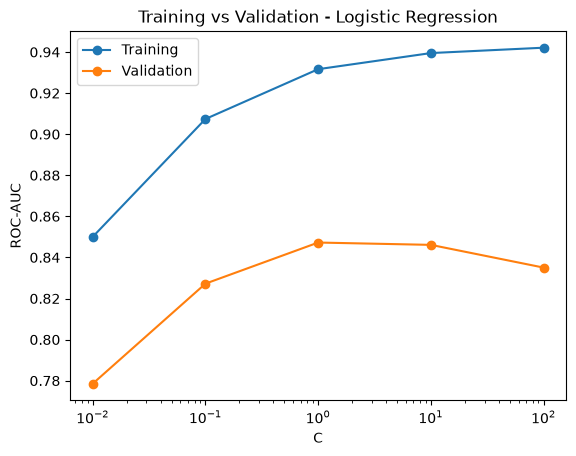

In [ ]:
results = pd.DataFrame(grid_search.cv_results_)

plt.plot(
    results["param_model__C"].astype(float),
    results["mean_train_score"],
    marker="o",
    label="Training"
)

plt.plot(
    results["param_model__C"].astype(float),
    results["mean_test_score"],
    marker="o",
    label="Validation"
)

plt.xscale("log")
plt.xlabel("C")
plt.ylabel("ROC-AUC")
plt.title("Training vs Validation - Logistic Regression")
plt.legend()
plt.show()

For Logistic regression we decided to tune the C parameter from the standard C=1 to C=10. This was done even though C=100 achieved a better score than the others. Our reasoning for this choice was mainly due to there being a microscopical difference between the results of C=10 and C=100, and the fact that we wanted to keep more of the regularization.  

In [ ]:
param_grid = {
    "model__n_estimators" : [100, 200],
    "model__max_depth" : [None, 3, 5, 10, 15, 20, 25, 30],
    "model__min_samples_leaf" : [1, 3, 5]
}

grid_search = GridSearchCV(estimator=models["Random Forest"],
                           param_grid=param_grid,
                           cv=cross_validation,
                           scoring="roc_auc",
                           return_train_score=True)

grid_search.fit(X_train_selected, y_train)


print("Best parameters: ", grid_search.best_params_)
print("Best score: ", grid_search.best_score_)

Best parameters:  {'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best score:  0.8253323751347466


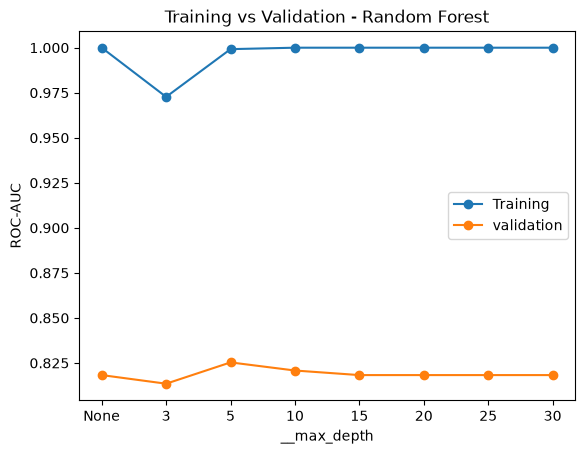

In [ ]:
# param = "model__max_depth"

# results = pd.DataFrame(grid_search.cv_results_)
# best = grid_search.best_params_

# others = {k: v for k, v in best.items() if k != param}
# results = results[results["params"].map(lambda p: all(p[k] == v for k, v in others.items()))]

# x = results[f"param_{param}"].map(str)

# plt.plot(x, results["mean_train_score"], marker="o", label="Training")
# plt.plot(x, results["mean_test_score"], marker="o", label="validation")

# plt.xlabel(param.replace("model", ""))
# plt.ylabel("ROC-AUC")
# plt.title("Training vs Validation - Random Forest")
# plt.legend()
# plt.show()

In [ ]:
# param_grid = [
#     {
#         "model__kernel" : ["linear"],
#         "model__C" : [0.1, 1, 10, 100] 
#     }, 
#     {
#         "model__kernel" : ["rbf"],
#         "model__C" : [0.1, 1, 10, 100],
#         "model__gamma" : [0.001, 0.01, 0.1, 1] 
#     }
# ]

# grid_search = GridSearchCV(estimator=models["SVM"],
#                            param_grid=param_grid,
#                            cv=cross_validation,
#                            scoring="roc_auc",
#                            return_train_score=True)

# grid_search.fit(X_train_selected, y_train)


# print("Best parameters: ", grid_search.best_params_)
# print("Best score: ", grid_search.best_score_)

Potensielt plotte noe likt som for Logistic regression. Virka litt komplisert da. Eventuelt plotte noe annet eller lage noe tabell. Ikke like lett å sammenligne da???

## Now we fit

Potensielt plotte noe likt som for Logistic regression. Virka litt komplisert da. Eventuelt plotte noe annet eller lage noe tabell. Ikke like lett å sammenligne da???

In [ ]:
model = models["Logistic Regression"]
model.fit(X_train, y_train)
# make predictions
y_pred = model.predict(X_test)

In [ ]:
print('Accuracy score: %.3f' % accuracy_score(y_test, y_pred))
print('F1-score: %.3f' % f1_score(y_test, y_pred))
print('Recall score: %.3f' % recall_score(y_test, y_pred))
print('Precision score: %.3f' % precision_score(y_test, y_pred))
print('ROC-AUC score: %.3f' % roc_auc_score(y_test, y_pred))

Accuracy score: 0.812
F1-score: 0.800
Recall score: 0.750
Precision score: 0.857
ROC-AUC score: 0.812


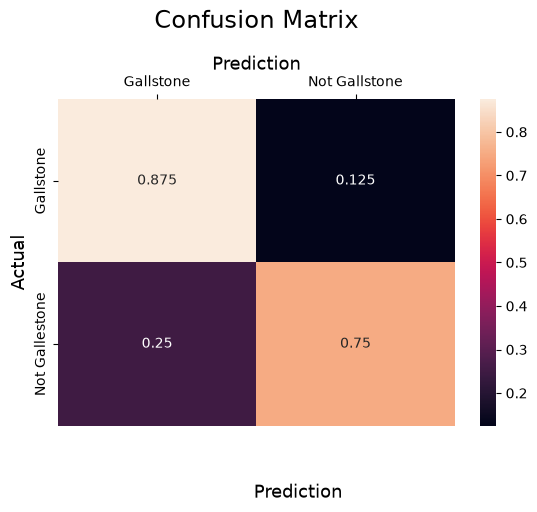

              precision    recall  f1-score   support

           0       0.78      0.88      0.82        24
           1       0.86      0.75      0.80        24

    accuracy                           0.81        48
   macro avg       0.82      0.81      0.81        48
weighted avg       0.82      0.81      0.81        48



In [ ]:
cm = confusion_matrix(y_test, y_pred, normalize='true')

sns.heatmap(cm, 
            annot=True,
            fmt='g', 
            xticklabels=['Gallstone','Not Gallstone'],
            yticklabels=['Gallstone','Not Gallestone'])
plt.ylabel('Actual', fontsize=13)
plt.title('Confusion Matrix', fontsize=17, pad=20)
plt.gca().xaxis.set_label_position('top') 
plt.xlabel('Prediction', fontsize=13)
plt.gca().xaxis.tick_top()

plt.gca().figure.subplots_adjust(bottom=0.2)
plt.gca().figure.text(0.5, 0.05, 'Prediction', ha='center', fontsize=13)
plt.show()
print(classification_report(y_test, y_pred))

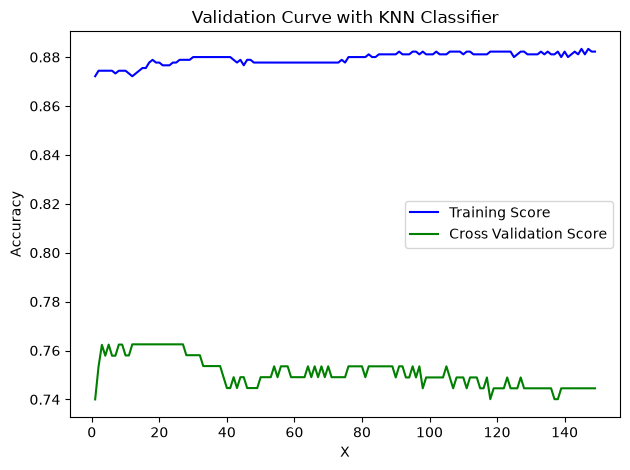

In [ ]:
parameter_range = np.arange(1, 150, 1)
train_score, test_score = validation_curve(estimator=models["Logistic Regression"], X=X_train, y=y_train,
                 param_name="model__C", param_range=parameter_range,
                                           cv=cross_validation, scoring="accuracy")

# Calculating mean and standard deviation of training score
mean_train_score = np.mean(train_score, axis=1)
std_train_score = np.std(train_score, axis=1)

# Calculating mean and standard deviation of testing score
mean_test_score = np.mean(test_score, axis=1)
std_test_score = np.std(test_score, axis=1)

# Plot mean accuracy scores for training and testing scores
plt.plot(parameter_range, mean_train_score,
         label="Training Score", color='b')
plt.plot(parameter_range, mean_test_score,
         label="Cross Validation Score", color='g')

# Creating the plot
plt.title("Validation Curve with KNN Classifier")
plt.xlabel("X")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.legend(loc='best')
plt.show()

### 5.4 Explainability

### 5.5 Checks

Learning curve, permutation test score

## 6. Conclusion